In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House1.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House10.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House11.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House12.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House13.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House15.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House16.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House17.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House18.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House19.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House2.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House20.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House21.csv
/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House3.csv
/kaggle/input/datasets/valorantphoeni

In [2]:
import pandas as pd

In [3]:
df1= pd.read_csv("/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House1.csv")

In [4]:
df1.head()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9,Issues
0,2013-10-09 13:06:17,1381323977,523,74,0,69,0,0,0,0,0,1,0
1,2013-10-09 13:06:31,1381323991,526,75,0,69,0,0,0,0,0,1,0
2,2013-10-09 13:06:46,1381324006,540,74,0,68,0,0,0,0,0,1,0
3,2013-10-09 13:07:01,1381324021,532,74,0,68,0,0,0,0,0,1,0
4,2013-10-09 13:07:15,1381324035,540,74,0,69,0,0,0,0,0,1,0


In [5]:
df2= pd.read_csv("/kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House2.csv")
df2.head()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9,Issues
0,2013-09-17 22:08:11,1379455691,695,88,0,0,0,0,0,0,0,0,0
1,2013-09-17 22:08:18,1379455698,694,88,0,0,0,0,0,0,0,0,0
2,2013-09-17 22:08:26,1379455706,694,88,0,0,0,0,0,0,0,0,0
3,2013-09-17 22:08:34,1379455714,702,88,0,0,0,0,0,0,0,0,0
4,2013-09-17 22:08:42,1379455722,700,88,0,0,0,0,0,0,0,0,0


In [6]:
import re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_ROOT = Path("/kaggle/input/datasets/valorantphoenix/refit-clean")                # jahan cleaned REFIT CSVs hain
OUT = Path("/kaggle/working/outputs/section2"); OUT.mkdir(parents=True, exist_ok=True)
CACHE = Path("/kaggle/working/cache"); CACHE.mkdir(parents=True, exist_ok=True)

# Washing-machine channel per house (from the REFIT README)
WM_CHANNEL = {1: "Appliance5", 2: "Appliance2", 3: "Appliance6", 5: "Appliance3",
              6: "Appliance2", 7: "Appliance5", 9: "Appliance3", 10: "Appliance5",
              15: "Appliance3", 16: "Appliance5", 17: "Appliance4", 19: "Appliance2",
              20: "Appliance4", 21: "Appliance3"}
CANDIDATES = [1, 2, 3, 5, 7, 9, 10]   # shuru me itne; baad me badha sakte ho

# cleaning (same logic as Section 1)
FREQ = "1min"
MAX_FILL_MIN = 5
MAX_AGG_W, MAX_APP_W = 15000, 4000
STUCK_MIN, STUCK_MIN_W = 60, 100

# washing-machine cycle rule
ON_W = 10            # active if power > 10 W
MERGE_GAP_MIN = 15   # off-gaps up to 15 min inside a cycle (soak/rinse pauses) are merged
MIN_DUR_MIN = 10     # cycle must last >= 10 min
MIN_WH = 20          # and use >= 20 Wh (removes standby blips)
TZ = "Europe/London"

In [7]:
all_csv = sorted(DATA_ROOT.rglob("CLEAN_House*.csv"))
print(len(all_csv), "clean files:", [p.name for p in all_csv])

def find_file(h):
    c = [p for p in all_csv if re.fullmatch(rf"CLEAN_House{h}\.csv", p.name)]
    if not c:
        raise FileNotFoundError(f"No file found for House {h}")
    return c[0]

p = find_file(CANDIDATES[0]); print("\nUsing", p)
t = pd.read_csv(p, nrows=3)
t["unix_utc"] = pd.to_datetime(t["Unix"], unit="s", utc=True)
t["unix_london"] = t["unix_utc"].dt.tz_convert(TZ)
print(t[["Time", "Unix", "unix_utc", "unix_london"]])

20 clean files: ['CLEAN_House1.csv', 'CLEAN_House10.csv', 'CLEAN_House11.csv', 'CLEAN_House12.csv', 'CLEAN_House13.csv', 'CLEAN_House15.csv', 'CLEAN_House16.csv', 'CLEAN_House17.csv', 'CLEAN_House18.csv', 'CLEAN_House19.csv', 'CLEAN_House2.csv', 'CLEAN_House20.csv', 'CLEAN_House21.csv', 'CLEAN_House3.csv', 'CLEAN_House4.csv', 'CLEAN_House5.csv', 'CLEAN_House6.csv', 'CLEAN_House7.csv', 'CLEAN_House8.csv', 'CLEAN_House9.csv']

Using /kaggle/input/datasets/valorantphoenix/refit-clean/CLEAN_House1.csv
                  Time        Unix                  unix_utc  \
0  2013-10-09 13:06:17  1381323977 2013-10-09 13:06:17+00:00   
1  2013-10-09 13:06:31  1381323991 2013-10-09 13:06:31+00:00   
2  2013-10-09 13:06:46  1381324006 2013-10-09 13:06:46+00:00   

                unix_london  
0 2013-10-09 14:06:17+01:00  
1 2013-10-09 14:06:31+01:00  
2 2013-10-09 14:06:46+01:00  


In [22]:
def fill_short(s, limit=MAX_FILL_MIN):
    """Interpolate gaps <= limit minutes; longer gaps stay NaN."""
    isn = s.isna()
    rid = (isn != isn.shift()).cumsum()
    rlen = isn.groupby(rid).transform("sum")
    long_gap = isn & (rlen > limit)
    return s.interpolate(method="time", limit=limit, limit_area="inside").mask(long_gap)

def flag_stuck(s, min_len=STUCK_MIN, min_w=STUCK_MIN_W):
    x = s.round(0)
    new_run = x.ne(x.shift()) | x.isna()
    rid = new_run.cumsum()
    rlen = x.groupby(rid).transform("size")
    return (rlen >= min_len) & (x > min_w) & x.notna()

def load_house_1min(h):
    cache = CACHE / f"house{h}_1min.pkl"
    if cache.exists():
        d = pd.read_pickle(cache)
        d["ok"] = d["valid"]          # Issues is NOT used to mask minutes
        return d
    p, wm = find_file(h), WM_CHANNEL[h]
    raw = pd.read_csv(p, usecols=lambda c: c.strip() in {"Unix", "Aggregate", wm, "Issues"})
    raw.columns = [c.strip() for c in raw.columns]
    raw = raw.rename(columns={"Unix": "unix", "Aggregate": "agg", wm: "wm", "Issues": "issues"})
    raw["ts"] = pd.to_datetime(raw["unix"], unit="s", utc=True)
    raw = raw.dropna(subset=["ts"])
    raw.loc[(raw["agg"] < 0) | (raw["agg"] > MAX_AGG_W), "agg"] = np.nan
    raw.loc[(raw["wm"] < 0) | (raw["wm"] > MAX_APP_W), "wm"] = np.nan

    g = raw.groupby("ts").agg(agg=("agg", "mean"), wm=("wm", "mean"), issues=("issues", "max"))
    m = g.resample(FREQ).agg({"agg": "mean", "wm": "mean", "issues": "max"})
    m = m.reindex(pd.date_range(m.index.min(), m.index.max(), freq=FREQ))

    d = pd.DataFrame(index=m.index)
    d["no_data"] = m["agg"].isna() | m["wm"].isna()          # minutes with no reading at all
    d["agg"] = fill_short(m["agg"])
    d["wm"] = fill_short(m["wm"])
    d["stuck"] = flag_stuck(d["agg"]) | flag_stuck(d["wm"])   # forward-fill plateaus
    d.loc[d["stuck"], ["agg", "wm"]] = np.nan
    d["issues_flag"] = m["issues"].fillna(0).eq(1)            # sum(IAMs) > aggregate
    d["valid"] = d["agg"].notna() & d["wm"].notna()
    d["ok"] = d["valid"] & ~d["issues_flag"]                  # used for analysis and modelling
    d = d.astype({"agg": "float32", "wm": "float32"})
    d.to_pickle(cache)
    return d

In [23]:
def detect_cycles(d):
    wm, ok = d["wm"], d["ok"]
    active = (wm > ON_W) & ok
    off = ~active
    rid = (off != off.shift()).cumsum()
    rlen = off.groupby(rid).transform("size")
    run_all_ok = ok.groupby(rid).transform("all")
    edge = (rid == rid.iloc[0]) | (rid == rid.iloc[-1])
    fill = off & run_all_ok & (rlen <= MERGE_GAP_MIN) & ~edge    # merge short valid pauses
    act = active | fill

    sid = (act != act.shift()).cumsum()
    t = pd.DataFrame({"t": d.index, "wm": wm.values, "sid": sid.values})[act.values]
    if t.empty:
        return pd.DataFrame(columns=["start", "end", "duration_min", "energy_wh",
                                     "peak_w", "mean_w", "censored"])
    c = t.groupby("sid").agg(start=("t", "min"), end=("t", "max"), duration_min=("t", "size"),
                             wm_sum=("wm", "sum"), peak_w=("wm", "max"), mean_w=("wm", "mean"))
    c["energy_wh"] = c["wm_sum"] / 60
    c = c.drop(columns="wm_sum")

    # censored = neighbouring minute before start / after end is not valid (cycle may be cut off)
    pos = pd.Series(np.arange(len(d)), index=d.index)
    s_pos, e_pos = pos[c["start"]].values, pos[c["end"]].values
    okv = ok.values
    before_ok = (s_pos > 0) & okv[np.maximum(s_pos - 1, 0)]
    after_ok = (e_pos < len(d) - 1) & okv[np.minimum(e_pos + 1, len(d) - 1)]
    c["censored"] = ~(before_ok & after_ok)
    iss = d["issues_flag"].astype(int).cumsum().values
    prev = np.where(s_pos > 0, iss[np.maximum(s_pos - 1, 0)], 0)
    c["has_issue"] = (iss[e_pos] - prev) > 0       # any Issues=1 minute inside the cycle
    c = c[(c["duration_min"] >= MIN_DUR_MIN) & (c["energy_wh"] >= MIN_WH)]
    return c.reset_index(drop=True)

In [24]:
DATA, CYC, rows = {}, {}, []
for h in CANDIDATES:
    try:
        d = load_house_1min(h)
    except Exception as e:
        print(f"House {h}: skipped ({e})"); continue
    c = detect_cycles(d)
    DATA[h], CYC[h] = d, c
    full = c[~c["censored"]]
    okm = d["ok"].sum()
    rows.append({
        "house": h, "channel": WM_CHANNEL[h],
        "first": d.index.min().date(), "last": d.index.max().date(),
        "minutes": len(d),
        "no_data_%": round(d["no_data"].mean() * 100, 1),
        "issues_%": round(d["issues_flag"].mean() * 100, 1),
        "stuck_%": round(d["stuck"].mean() * 100, 2),
        "valid_%": round(d["ok"].mean() * 100, 1),
        
        "off_time_%": round(((d["wm"] <= ON_W) & d["ok"]).sum() / max(okm, 1) * 100, 1),
        "cycles": len(c), "complete_cycles": len(full),
        "cycles_per_week": round(len(full) / max(okm / (60 * 24 * 7), 1e-9), 2),
        "median_dur_min": full["duration_min"].median(),
        "median_Wh": round(full["energy_wh"].median(), 0),
        "median_peak_W": round(full["peak_w"].median(), 0),
        "cycles_with_issue_%": round(full["has_issue"].mean() * 100, 1) if len(full) else np.nan,
    })
summary = pd.DataFrame(rows).set_index("house")
summary.to_csv(OUT / "washing_machine_summary.csv")
print(summary.to_string())

          channel       first        last  minutes  no_data_%  issues_%  stuck_%  valid_%  off_time_%  cycles  complete_cycles  cycles_per_week  median_dur_min  median_Wh  median_peak_W  cycles_with_issue_%
house                                                                                                                                                                                                         
1      Appliance5  2013-10-09  2015-07-10   920091       12.6       1.8     0.32     87.1        98.0     390              372             4.68            34.0      319.0         2325.0                 97.6
2      Appliance2  2013-09-17  2015-05-28   889078       24.6       1.5     0.46     75.0        95.0     327              298             4.51           101.0      639.0         2091.0                 97.7
3      Appliance6  2013-09-25  2015-06-02   885095       11.4       6.9    12.05     76.7        94.1     598              539             8.01            67.0      555.0  

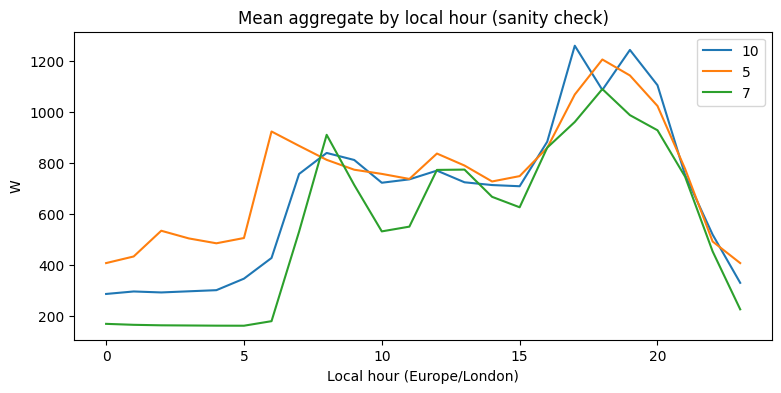

10    0
5     0
7     5
dtype: int32 10    17
5     18
7     18
dtype: int32


In [25]:
# Average aggregate load by local hour: UK homes typically trough ~03-05h, peak ~18-20h
prof = {}
for h in HOUSES_USED if "HOUSES_USED" in globals() else DATA:
    d = DATA[h]
    a = d["agg"].where(d["ok"])
    a.index = a.index.tz_localize("UTC").tz_convert(TZ) if a.index.tz is None else a.index.tz_convert(TZ)
    prof[h] = a.groupby(a.index.hour).mean()
prof = pd.DataFrame(prof)
prof.plot(figsize=(9, 4), title="Mean aggregate by local hour (sanity check)")
plt.xlabel("Local hour (Europe/London)"); plt.ylabel("W"); plt.show()
print(prof.idxmin(), prof.idxmax())

In [26]:
for h, d in DATA.items():
    act = (d["wm"] > ON_W) & d["valid"]
    print(h,
          "| Issues rate overall: %.1f%%" % (d.loc[d["valid"], "issues_flag"].mean() * 100),
          "| while washer ON: %.1f%%" % (d.loc[act, "issues_flag"].mean() * 100))

1 | Issues rate overall: 2.1% | while washer ON: 30.4%
2 | Issues rate overall: 2.0% | while washer ON: 16.0%
3 | Issues rate overall: 7.1% | while washer ON: 23.6%
5 | Issues rate overall: 7.5% | while washer ON: 21.1%
7 | Issues rate overall: 4.7% | while washer ON: 23.1%
9 | Issues rate overall: 2.5% | while washer ON: 30.1%
10 | Issues rate overall: 2.0% | while washer ON: 11.8%


In [27]:
orig = MERGE_GAP_MIN
rows = []
for gap in [5, 15, 30, 60]:
    MERGE_GAP_MIN = gap
    for h in [1, 5, 7, 10]:
        c = detect_cycles(DATA[h]); c = c[~c["censored"]]
        rows.append({"gap_min": gap, "house": h, "cycles": len(c),
                     "median_dur": c["duration_min"].median(),
                     "median_Wh": round(c["energy_wh"].median())})
MERGE_GAP_MIN = orig
print(pd.DataFrame(rows).pivot(index="house", columns="gap_min",
                               values=["cycles", "median_dur", "median_Wh"]).to_string())

        cycles                      median_dur                      median_Wh                     
gap_min     5      15     30     60         5      15     30     60        5      15     30     60
house                                                                                             
1        408.0  372.0  359.0  351.0       33.0   34.0   34.0   34.0     306.0  319.0  322.0  330.0
5        815.0  712.0  641.0  522.0       42.0   47.0   56.0   78.0     267.0  288.0  312.0  364.0
7        863.0  820.0  788.0  749.0       61.0   61.0   62.0   63.0     534.0  551.0  562.0  576.0
10       622.0  581.0  549.0  530.0      120.0  121.0  121.0  121.0     707.0  715.0  719.0  722.0


count    372.0
mean      44.0
std       30.0
min       10.0
10%       32.0
25%       33.0
50%       34.0
75%       36.0
90%       74.0
max      272.0
Name: duration_min, dtype: float64


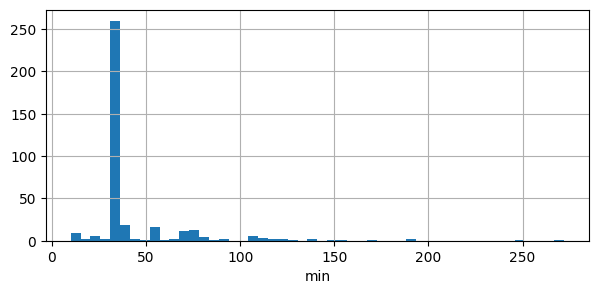

In [28]:
c = CYC[1][~CYC[1]["censored"]]
print(c["duration_min"].describe(percentiles=[.1, .25, .5, .75, .9]).round(0))
c["duration_min"].clip(upper=300).hist(bins=50, figsize=(7, 3)); plt.xlabel("min"); plt.show()

In [29]:
eligible = summary[(summary["complete_cycles"] >= 30) & (summary["valid_%"] >= 40)]
HOUSES_USED = eligible.sort_values("complete_cycles", ascending=False).index.tolist()
print("Houses used:", HOUSES_USED)
assert len(HOUSES_USED) >= 4, "Need >= 4 houses: add more to CANDIDATES (e.g. 15, 16, 17, 19, 20, 21)"

Houses used: [7, 5, 10, 3, 1, 2, 9]


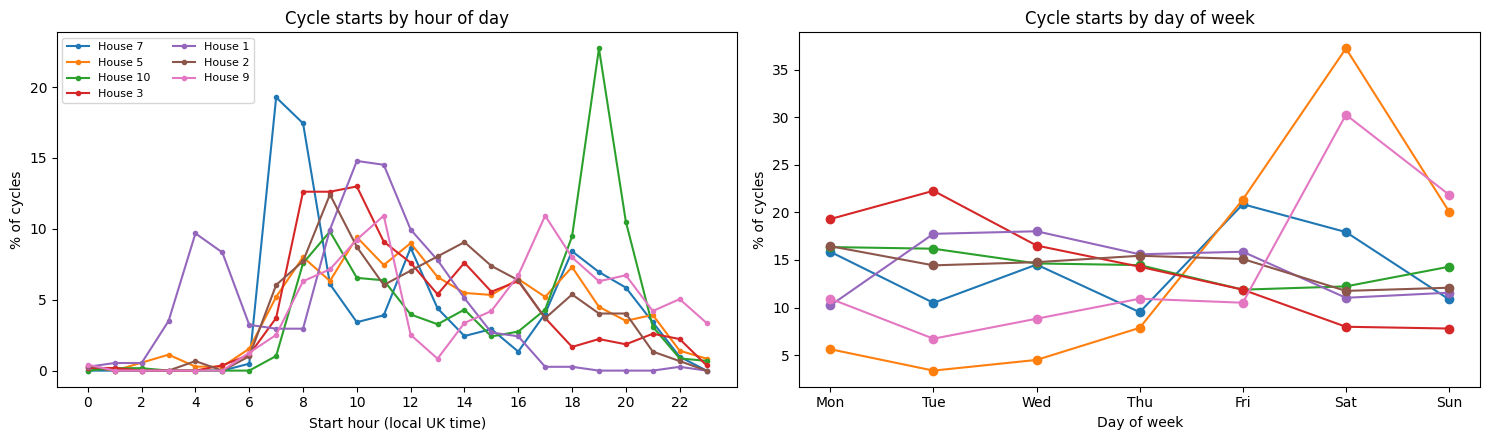

In [30]:
starts = {}
for h in HOUSES_USED:
    c = CYC[h][~CYC[h]["censored"]]
    starts[h] = c["start"].dt.tz_convert(TZ)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for h in HOUSES_USED:
    share_h = starts[h].dt.hour.value_counts(normalize=True).reindex(range(24), fill_value=0)
    axes[0].plot(range(24), share_h.values * 100, marker="o", ms=3, label=f"House {h}")
    share_d = starts[h].dt.dayofweek.value_counts(normalize=True).reindex(range(7), fill_value=0)
    axes[1].plot(range(7), share_d.values * 100, marker="o", label=f"House {h}")
axes[0].set(xlabel="Start hour (local UK time)", ylabel="% of cycles",
            title="Cycle starts by hour of day"); axes[0].set_xticks(range(0, 24, 2))
axes[1].set(xlabel="Day of week", ylabel="% of cycles", title="Cycle starts by day of week")
axes[1].set_xticks(range(7)); axes[1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[0].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "usage_hour_dow.png", dpi=130); plt.show()

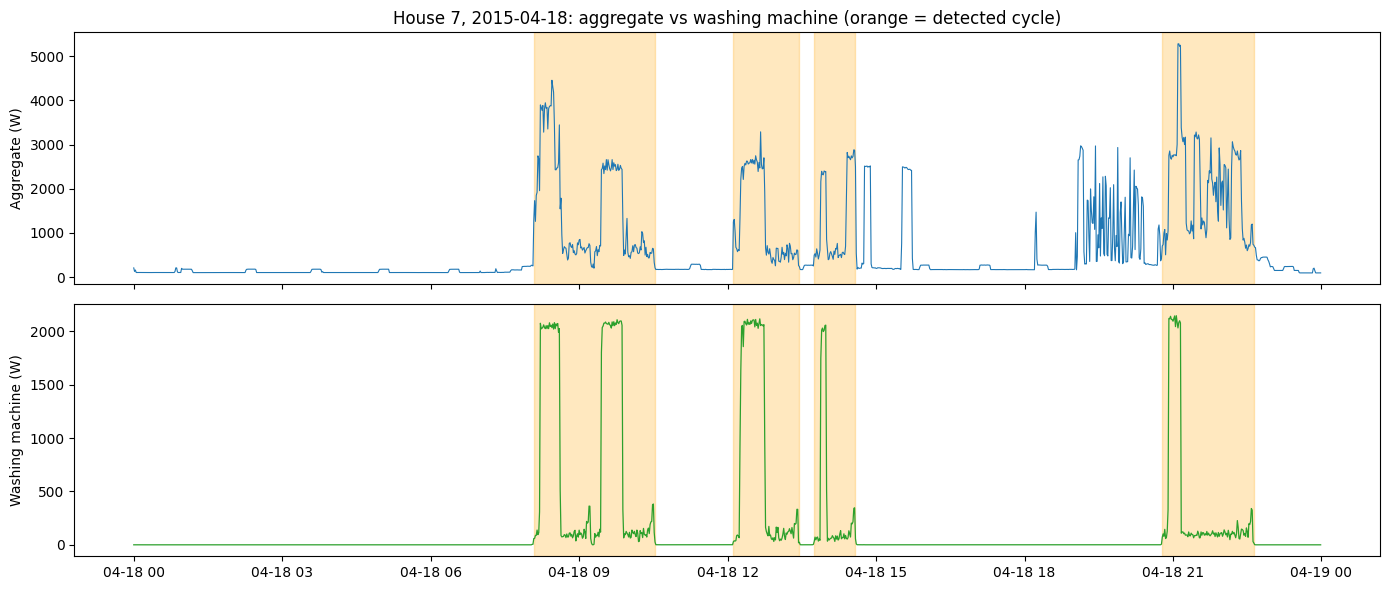

In [31]:
h = HOUSES_USED[0]
d, c = DATA[h], CYC[h]
dl = d.copy(); dl.index = dl.index.tz_convert(TZ)
cov = dl["ok"].resample("D").mean()
energy = dl["wm"].where(dl["ok"]).resample("D").sum() / 60
cand = energy[cov > 0.95]
day = cand.idxmax()
w = dl.loc[day: day + pd.Timedelta(days=1) - pd.Timedelta(minutes=1)]

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax[0].plot(w.index, w["agg"], lw=0.8); ax[0].set_ylabel("Aggregate (W)")
ax[1].plot(w.index, w["wm"], lw=0.9, color="tab:green"); ax[1].set_ylabel("Washing machine (W)")
cl = c.copy(); cl["start"] = cl["start"].dt.tz_convert(TZ); cl["end"] = cl["end"].dt.tz_convert(TZ)
for _, r in cl[(cl["start"] >= w.index[0]) & (cl["start"] <= w.index[-1])].iterrows():
    for a in ax:
        a.axvspan(r["start"], r["end"], color="orange", alpha=0.25)
ax[0].set_title(f"House {h}, {day.date()}: aggregate vs washing machine (orange = detected cycle)")
plt.tight_layout(); plt.savefig(OUT / "trace_24h.png", dpi=130); plt.show()

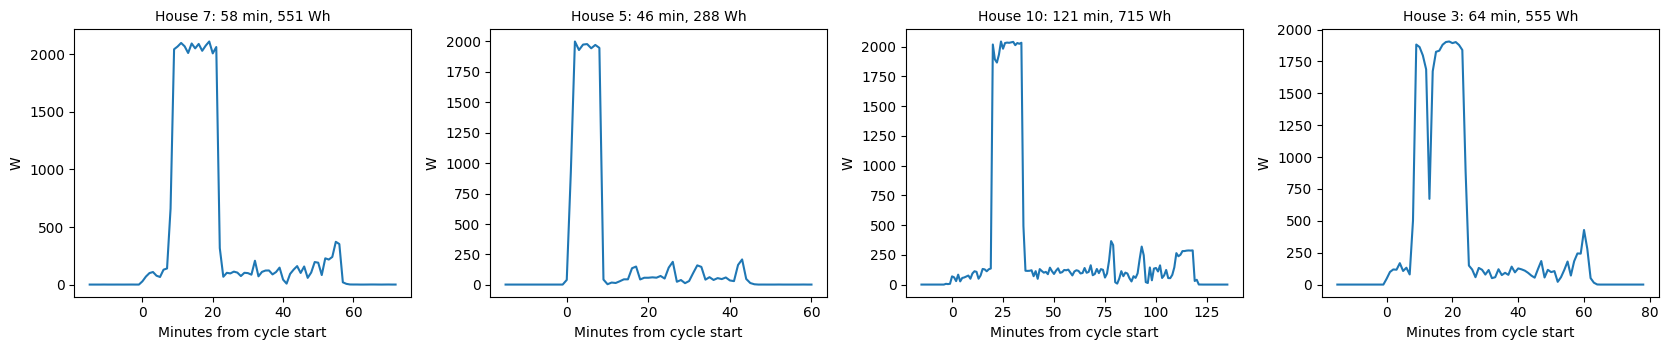

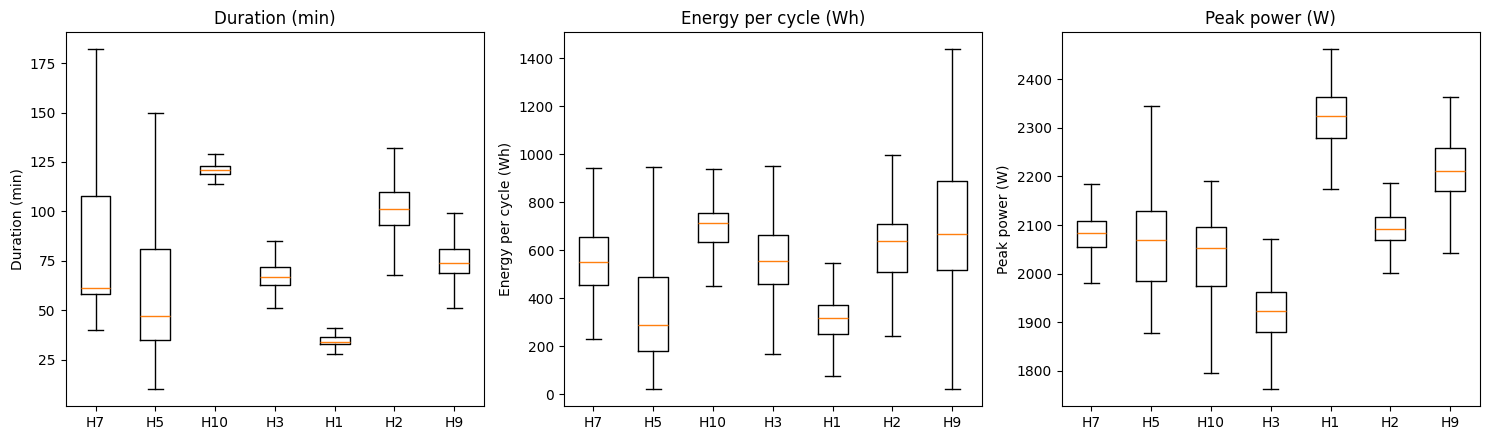

In [32]:
# (ii) one representative (median-energy) complete cycle per house
shown = HOUSES_USED[:4]
fig, axes = plt.subplots(1, len(shown), figsize=(4.2 * len(shown), 3.6))
for ax, h in zip(np.atleast_1d(axes), shown):
    c = CYC[h][~CYC[h]["censored"]]
    r = c.iloc[(c["energy_wh"] - c["energy_wh"].median()).abs().argmin()]
    pad = pd.Timedelta(minutes=15)
    seg = DATA[h].loc[r["start"] - pad: r["end"] + pad, "wm"]
    ax.plot(np.arange(len(seg)) - 15, seg.values)
    ax.set_title(f"House {h}: {int(r['duration_min'])} min, {r['energy_wh']:.0f} Wh", fontsize=10)
    ax.set_xlabel("Minutes from cycle start"); ax.set_ylabel("W")
plt.tight_layout(); plt.savefig(OUT / "example_cycles.png", dpi=130); plt.show()

# (iii) cross-house comparison of cycle characteristics
metrics = [("duration_min", "Duration (min)"), ("energy_wh", "Energy per cycle (Wh)"),
           ("peak_w", "Peak power (W)")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, lab) in zip(axes, metrics):
    data = [CYC[h].loc[~CYC[h]["censored"], col].values for h in HOUSES_USED]
    ax.boxplot(data, showfliers=False)
    ax.set_xticklabels([f"H{h}" for h in HOUSES_USED]); ax.set_ylabel(lab)
    ax.set_title(lab)
plt.tight_layout(); plt.savefig(OUT / "cross_house_comparison.png", dpi=130); plt.show()

In [33]:
!ls -lh /kaggle/working/outputs/section2

total 508K
-rw-r--r-- 1 root root  57K Oct 29 11:51 cross_house_comparison.png
-rw-r--r-- 1 root root  98K Oct 29 11:51 example_cycles.png
-rw-r--r-- 1 root root 128K Oct 29 11:51 trace_24h.png
-rw-r--r-- 1 root root 214K Oct 29 11:51 usage_hour_dow.png
-rw-r--r-- 1 root root  894 Oct 29 11:51 washing_machine_summary.csv


In [34]:
c = CYC[1][~CYC[1]["censored"]]; s = c["start"].dt.tz_convert(TZ)
print(c[s.dt.hour.between(3, 5)]["duration_min"].describe())

count    80.000000
mean     35.625000
std       6.461914
min      25.000000
25%      32.000000
50%      33.500000
75%      35.000000
max      56.000000
Name: duration_min, dtype: float64


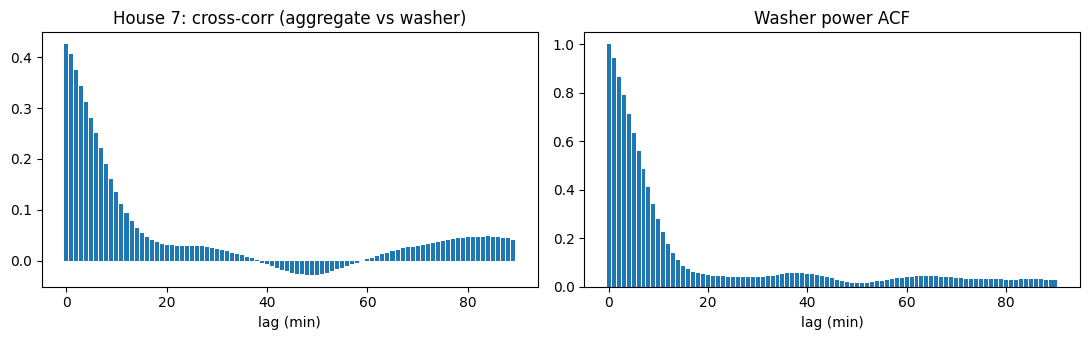

In [35]:
from statsmodels.tsa.stattools import ccf, acf   # pip install statsmodels agar na ho

h = 7
d = DATA[h]
x = d["agg"].where(d["ok"]).interpolate(limit=5).dropna()
y = d["wm"].reindex(x.index)
x = x[y.notna()]; y = y[y.notna()]
# aggregate minus slow baseline, so we look at the changes the washer causes
xd = x - x.rolling(120, center=True, min_periods=30).median()

lags = 90
cc_pos = ccf(xd.values, y.values, adjusted=False)[:lags]   # agg leads washer
ac = acf(y.values, nlags=lags, fft=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(range(lags), cc_pos); ax[0].set_title(f"House {h}: cross-corr (aggregate vs washer)"); ax[0].set_xlabel("lag (min)")
ax[1].bar(range(lags + 1), ac); ax[1].set_title("Washer power ACF"); ax[1].set_xlabel("lag (min)")
plt.tight_layout(); plt.show()

In [36]:
for h in [1, 2, 3, 5, 7, 9, 10]:
    d = DATA[h]
    print(h, "| ok%:", round(d["ok"].mean() * 100, 1), "| valid%:", round(d["valid"].mean() * 100, 1),
          "| cycles:", len(CYC[h]))
assert all((DATA[h]["ok"] == DATA[h]["valid"]).all() for h in DATA), "ok != valid: Issues is still masking minutes"

1 | ok%: 87.1 | valid%: 87.1 | cycles: 390
2 | ok%: 75.0 | valid%: 75.0 | cycles: 327
3 | ok%: 76.7 | valid%: 76.7 | cycles: 598
5 | ok%: 89.3 | valid%: 89.3 | cycles: 761
7 | ok%: 86.9 | valid%: 86.9 | cycles: 836
9 | ok%: 80.0 | valid%: 80.0 | cycles: 244
10 | ok%: 81.2 | valid%: 81.2 | cycles: 610


In [37]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
warnings.filterwarnings("ignore")

OUT3 = Path("/kaggle/working/outputs/section3"); OUT3.mkdir(parents=True, exist_ok=True)

# Split by HOUSEHOLD (no house appears in two sets)
TRAIN_H, VAL_H, TEST_H = [1, 2, 3, 9], [5], [7, 10]
missing = [h for h in TRAIN_H + VAL_H + TEST_H if h not in DATA]
assert not missing, f"Houses not loaded in Section 2: {missing}"
assert not (set(TRAIN_H) & set(VAL_H)) and not (set(TRAIN_H + VAL_H) & set(TEST_H))

ON_W = 10          # ON/OFF threshold for metrics (same as the cycle rule)
OFF_KEEP = 0.3     # keep 30% of OFF minutes in TRAINING only (speed); val/test are never subsampled
SEED = 42
N_EST_ABL, N_EST_FINAL = 300, 800

In [38]:
def make_features(d, W=15, roll=(5, 15, 30, 60)):
    """Features from the AGGREGATE only (never from appliance channels).
    Uses past AND future minutes (offline / non-causal estimation)."""
    a = d["agg"].astype("float32")
    F = {"agg": a}
    for k in range(1, W + 1):
        F[f"lag{k}"] = a.shift(k)
        F[f"lead{k}"] = a.shift(-k)
    for w in roll:
        r = a.rolling(w, center=True, min_periods=max(2, w // 3))
        F[f"mean{w}"] = r.mean(); F[f"std{w}"] = r.std()
        F[f"min{w}"] = r.min();   F[f"max{w}"] = r.max()
    F["diff1"] = a.diff()
    F["diff_lead1"] = a.shift(-1) - a
    base = a.rolling(120, center=True, min_periods=30).median()   # slow baseline (fridge, standby)
    F["base120"] = base
    F["agg_minus_base"] = a - base
    idx = d.index.tz_convert(TZ) if d.index.tz is not None else d.index.tz_localize("UTC").tz_convert(TZ)
    F["hour"] = pd.Series(idx.hour, index=d.index, dtype="float32")
    F["dow"] = pd.Series(idx.dayofweek, index=d.index, dtype="float32")
    return pd.DataFrame(F).astype("float32")

_cache = {}
def get_house(h, W):
    """Rows = minutes where aggregate AND washer are valid. Returns (X, y, meta)."""
    key = (h, W)
    if key not in _cache:
        d = DATA[h]; m = d["ok"].values
        X = make_features(d, W).loc[m]
        y = d["wm"].loc[m].astype("float32")
        meta = pd.DataFrame({"issues": d["issues_flag"].loc[m].values,
                             "hour": X["hour"].values.astype(int)}, index=X.index)
        _cache[key] = (X, y, meta)
    return _cache[key]

def stack(houses, W, off_keep=1.0, seed=SEED):
    rng = np.random.default_rng(seed); Xs, ys = [], []
    for h in houses:
        X, y, _ = get_house(h, W)
        if off_keep < 1.0:
            keep = (y.values > ON_W) | (rng.random(len(y)) < off_keep)
            X, y = X[keep], y[keep]
        Xs.append(X); ys.append(y)
    return pd.concat(Xs), pd.concat(ys)

In [39]:
def metrics(y, p, thr=ON_W):
    y = np.asarray(y, float); p = np.asarray(p, float)
    yt, pt = y > thr, p > thr
    tp = int((yt & pt).sum()); fp = int((~yt & pt).sum()); fn = int((yt & ~pt).sum())
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * prec * rec / (prec + rec) if tp > 0 else 0.0
    return {"MAE_W": np.abs(p - y).mean(), "RMSE_W": np.sqrt(((p - y) ** 2).mean()),
            "MAE_on_W": np.abs(p - y)[yt].mean() if yt.any() else np.nan,
            "SAE": abs(p.sum() - y.sum()) / max(y.sum(), 1e-9),
            "precision": prec, "recall": rec, "F1": f1,
            "true_Wh": y.sum() / 60, "pred_Wh": p.sum() / 60}

def postprocess(p, cut):
    p = np.clip(np.asarray(p, float), 0, None)
    p[p < cut] = 0.0
    return p

def hour_profile(houses, W=0):
    """Baseline 2: mean washer power per local hour, learned on the training houses."""
    ys = pd.concat([get_house(h, W)[1] for h in houses]).values
    hrs = np.concatenate([get_house(h, W)[2]["hour"].values for h in houses])
    return pd.Series(ys).groupby(hrs).mean()

def fit_lgb(Xtr, ytr, Xva, yva, n_est, w=None):
    m = lgb.LGBMRegressor(n_estimators=n_est, learning_rate=0.05, num_leaves=63,
                          min_child_samples=50, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.7, reg_lambda=1.0, metric="l2",
                          n_jobs=-1, random_state=SEED, verbose=-1)
    m.fit(Xtr, ytr, sample_weight=w, eval_set=[(Xva, yva)],
          callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)])
    return m

def sw(y):
    """ON minutes weight 1; kept OFF minutes weight 1/OFF_KEEP (undo the sampling)."""
    return np.where(np.asarray(y) > ON_W, 1.0, 1.0 / OFF_KEEP)

In [40]:
# Train on TRAIN houses, score on the VALIDATION house only (test untouched)
rows = []
for W in [0, 5, 15, 30]:
    Xtr, ytr = stack(TRAIN_H, W, OFF_KEEP)
    Xva, yva, _ = get_house(VAL_H[0], W)
    m = fit_lgb(Xtr, ytr, Xva, yva, N_EST_ABL, sw(ytr))
    r = metrics(yva, postprocess(m.predict(Xva), ON_W))
    rows.append({"lags_each_side_min": W, "n_features": Xtr.shape[1], "best_iter": m.best_iteration_,
                 **{k: r[k] for k in ["MAE_W", "SAE", "precision", "recall", "F1"]}})
    del Xtr, ytr
abl = pd.DataFrame(rows).set_index("lags_each_side_min")
print(abl.round(3).to_string())
abl.to_csv(OUT3 / "window_ablation_val.csv")
BEST_W = int(abl["F1"].idxmax())      # picked on VALIDATION F1
print("BEST_W =", BEST_W)
_cache = {k: v for k, v in _cache.items() if k[1] in (0, BEST_W)}   # free memory

                    n_features  best_iter   MAE_W    SAE  precision  recall     F1
lags_each_side_min                                                                
0                           23         32  33.309  0.353      0.178   0.611  0.275
5                           33         43  33.678  0.323      0.183   0.612  0.281
15                          53         27  32.998  0.382      0.174   0.611  0.271
30                          83         28  32.882  0.386      0.175   0.609  0.272
BEST_W = 5


In [41]:
Xtr, ytr = stack(TRAIN_H, BEST_W, OFF_KEEP)
Xva, yva, _ = get_house(VAL_H[0], BEST_W)
model = fit_lgb(Xtr, ytr, Xva, yva, N_EST_FINAL, sw(ytr))
print("trees used:", model.best_iteration_, "| train rows:", len(Xtr), "| features:", Xtr.shape[1])

# Choose the small-prediction cut-off on VALIDATION (turn tiny predictions into 0)
pv = model.predict(Xva)
tune = []
for cut in [0, 10, 25, 50, 75, 100, 150]:
    r = metrics(yva, postprocess(pv, cut)); tune.append({"cut_W": cut, **{k: r[k] for k in ["MAE_W", "SAE", "F1"]}})
tune = pd.DataFrame(tune).set_index("cut_W"); print(tune.round(3).to_string())
CUT = int(tune["F1"].idxmax()); print("CUT =", CUT)

trees used: 43 | train rows: 916103 | features: 33
        MAE_W    SAE     F1
cut_W                      
0      34.583  0.202  0.281
10     33.678  0.323  0.281
25     32.719  0.395  0.280
50     31.730  0.464  0.255
75     31.064  0.512  0.225
100    30.513  0.549  0.203
150    29.532  0.611  0.173
CUT = 0


In [42]:
# D1: baselines vs model on the VALIDATION house, plus class prior check
Xva, yva, mva = get_house(5, BEST_W)
pv = model.predict(Xva)
prof = hour_profile(TRAIN_H)
cands = {"always-off": np.zeros(len(yva)),
         "hour profile": prof.reindex(mva["hour"].values).fillna(0).values,
         "LightGBM": postprocess(pv, CUT)}
for name, p in cands.items():
    r = metrics(yva, p)
    print(f"{name:13s} MAE {r['MAE_W']:.1f} | SAE {r['SAE']:.2f} | P {r['precision']:.2f} R {r['recall']:.2f} F1 {r['F1']:.2f}")
full_on = np.mean(np.concatenate([(get_house(h, BEST_W)[1].values > ON_W) for h in TRAIN_H]))
print("ON share  train(full): %.3f | train(sampled): %.3f | val: %.3f" % (full_on, (ytr.values > ON_W).mean(), (yva.values > ON_W).mean()))

always-off    MAE 24.6 | SAE 1.00 | P nan R 0.00 F1 0.00
hour profile  MAE 37.4 | SAE 0.26 | P 0.09 R 0.79 F1 0.16
LightGBM      MAE 34.6 | SAE 0.20 | P 0.18 R 0.61 F1 0.28
ON share  train(full): 0.039 | train(sampled): 0.118 | val: 0.070


In [43]:
Xva, yva, mva = get_house(5, BEST_W)
pv = postprocess(model.predict(Xva), CUT)
for thr, lab in [(10, "any activity (>10 W)"), (500, "heating phase (>500 W)")]:
    r = metrics(yva, pv, thr=thr)
    print(f"{lab:24s} P {r['precision']:.2f} R {r['recall']:.2f} F1 {r['F1']:.2f}")

any activity (>10 W)     P 0.18 R 0.61 F1 0.28
heating phase (>500 W)   P 0.25 R 0.13 F1 0.17


In [44]:
POOL = TRAIN_H + VAL_H          # [1, 2, 3, 9, 5]; test houses 7, 10 stay untouched
W_FIX, N_TREES = 15, 150        # fixed trees: no early stopping on the held-out house
oof, rows = {}, []
for ho in POOL:
    tr = [h for h in POOL if h != ho]
    Xtr_, ytr_ = stack(tr, W_FIX, OFF_KEEP)
    Xho, yho, mho = get_house(ho, W_FIX)
    m = lgb.LGBMRegressor(n_estimators=N_TREES, learning_rate=0.05, num_leaves=63, min_child_samples=50,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
                          n_jobs=-1, random_state=SEED, verbose=-1)
    m.fit(Xtr_, ytr_, sample_weight=sw(ytr_))
    raw = m.predict(Xho); oof[ho] = (yho.values, raw)
    prof_ = hour_profile(tr)
    for name, p in [("always-off", np.zeros(len(yho))),
                    ("hour profile", prof_.reindex(mho["hour"].values).fillna(0).values),
                    ("LightGBM", postprocess(raw, CUT))]:
        r10, r500 = metrics(yho, p), metrics(yho, p, thr=500)
        rows.append({"held_out": ho, "model": name, "MAE": r10["MAE_W"], "SAE": r10["SAE"],
                     "F1_10W": r10["F1"], "F1_500W": r500["F1"]})
    print("done", ho)
loho = pd.DataFrame(rows).pivot(index="held_out", columns="model", values=["F1_10W", "F1_500W", "SAE"])
print(loho.round(2).to_string())
print("\nmean over held-out houses:\n", pd.DataFrame(rows).groupby("model")[["MAE", "SAE", "F1_10W", "F1_500W"]].mean().round(3))

# cut-off chosen on pooled out-of-fold predictions
yy = np.concatenate([oof[h][0] for h in POOL]); pp = np.concatenate([oof[h][1] for h in POOL])
print(pd.DataFrame([{"cut_W": c, **{k: metrics(yy, postprocess(pp, c))[k] for k in ["SAE", "precision", "recall", "F1"]}}
                    for c in [0, 25, 50, 100, 150, 250]]).set_index("cut_W").round(3).to_string())

done 1
done 2
done 3
done 9
done 5
           F1_10W                          F1_500W                              SAE                        
model    LightGBM always-off hour profile LightGBM always-off hour profile LightGBM always-off hour profile
held_out                                                                                                   
1            0.17        0.0         0.05     0.23        0.0          0.0     0.44        1.0         1.13
2            0.29        0.0         0.14     0.20        0.0          0.0     0.36        1.0         0.10
3            0.31        0.0         0.16     0.38        0.0          0.0     0.38        1.0         0.41
5            0.31        0.0         0.16     0.19        0.0          0.0     0.20        1.0         0.26
9            0.23        0.0         0.08     0.39        0.0          0.0     0.50        1.0         0.28

mean over held-out houses:
                  MAE    SAE  F1_10W  F1_500W
model                      

In [45]:
def cycle_eval_oof(h, p, idx):
    d = DATA[h]; s = pd.Series(np.nan, index=d.index); s.loc[idx] = p
    dp = d.copy(); dp["wm"] = s
    ct, cp = CYC[h].copy(), detect_cycles(dp)
    hit = lambda a, bs: bool(((bs["start"] <= a["end"]) & (bs["end"] >= a["start"])).any()) if len(bs) else False
    ct["detected"] = [hit(r, cp) for _, r in ct.iterrows()]
    ct["pred_wh"] = [s.loc[r["start"]:r["end"]].sum() / 60 for _, r in ct.iterrows()]
    prec = np.mean([hit(r, ct) for _, r in cp.iterrows()]) if len(cp) else np.nan
    return {"true_cycles": len(ct), "pred_cycles": len(cp), "cycle_recall": ct["detected"].mean(),
            "cycle_precision": prec,
            "median_abs_energy_err_%": (100 * (ct["pred_wh"] - ct["energy_wh"]).abs() / ct["energy_wh"]).median()}

rows = []
for ho in POOL:
    y_, raw_ = oof[ho]
    rows.append({"held_out": ho, **cycle_eval_oof(ho, postprocess(raw_, CUT), get_house(ho, W_FIX)[0].index)})
cyc_loho = pd.DataFrame(rows).set_index("held_out"); print(cyc_loho.round(2).to_string())
print(cyc_loho.mean().round(2))

          true_cycles  pred_cycles  cycle_recall  cycle_precision  median_abs_energy_err_%
held_out                                                                                  
1                 390          990          0.92             0.35                    86.38
2                 327         1028          0.86             0.28                    88.26
3                 598         1443          0.95             0.33                    59.13
9                 244         1218          1.00             0.18                    63.08
5                 761         2092          0.91             0.27                    78.36
true_cycles                 464.00
pred_cycles                1354.20
cycle_recall                  0.93
cycle_precision               0.28
median_abs_energy_err_%      75.04
dtype: float64


In [46]:
def two_stage_fit(Xtr, ytr, w):
    P_ = dict(n_estimators=150, learning_rate=0.05, num_leaves=63, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.7, n_jobs=-1,
              random_state=SEED, verbose=-1)
    on = ytr.values > ON_W
    clf = lgb.LGBMClassifier(**P_).fit(Xtr, on.astype(int), sample_weight=w)
    reg = lgb.LGBMRegressor(**P_).fit(Xtr[on], ytr[on])        # power only where the washer is ON
    return clf, reg

oof2 = {}
for ho in POOL:
    tr = [h for h in POOL if h != ho]
    Xtr_, ytr_ = stack(tr, W_FIX, OFF_KEEP)
    clf, reg = two_stage_fit(Xtr_, ytr_, sw(ytr_))
    Xho, yho, _ = get_house(ho, W_FIX)
    oof2[ho] = (yho.values, clf.predict_proba(Xho)[:, 1], np.clip(reg.predict(Xho), 0, None))
    print("done", ho)

yy = np.concatenate([oof2[h][0] for h in POOL])
pr = np.concatenate([oof2[h][1] for h in POOL]); rg = np.concatenate([oof2[h][2] for h in POOL])
sweep = pd.DataFrame([{"prob_thr": t, **{k: metrics(yy, np.where(pr >= t, rg, 0))[k]
                       for k in ["SAE", "precision", "recall", "F1"]}}
                      for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]]).set_index("prob_thr")
print(sweep.round(3).to_string())
T = float(sweep["F1"].idxmax()); print("best threshold:", T)
rows = []
for h in POOL:
    y_, p_, r_ = oof2[h]; m_ = metrics(y_, np.where(p_ >= T, r_, 0)); rows.append({"held_out": h, **{k: m_[k] for k in ["SAE", "precision", "recall", "F1"]}})
print(pd.DataFrame(rows).set_index("held_out").round(2).to_string())

done 1
done 2
done 3
done 9
done 5
            SAE  precision  recall     F1
prob_thr                                 
0.2       0.632      0.312   0.451  0.369
0.3       0.062      0.374   0.325  0.348
0.4       0.341      0.422   0.222  0.291
0.5       0.623      0.464   0.143  0.219
0.6       0.817      0.550   0.089  0.154
0.7       0.925      0.628   0.051  0.093
0.8       0.977      0.687   0.023  0.045
best threshold: 0.2
           SAE  precision  recall    F1
held_out                               
1         0.69       0.22    0.60  0.32
2         0.33       0.30    0.16  0.21
3         1.29       0.35    0.71  0.47
9         1.56       0.29    0.80  0.42
5         0.07       0.36    0.29  0.32


In [47]:
def with_leak(h, W):
    X, y, _ = get_house(h, W)
    X2 = X.copy()
    X2["LEAK_wm_lag1"] = DATA[h]["wm"].shift(1).loc[X.index].values
    return X2, y

Xs, ys = [], []
for h in [1, 2, 3, 9]:
    X2, y2 = with_leak(h, 15); Xs.append(X2); ys.append(y2)
Xtr_l, ytr_l = pd.concat(Xs), pd.concat(ys)
Xva_l, yva_l = with_leak(5, 15)
m_l = lgb.LGBMRegressor(n_estimators=100, learning_rate=0.05, num_leaves=63,
                        n_jobs=-1, random_state=SEED, verbose=-1).fit(Xtr_l, ytr_l)
r = metrics(yva_l, postprocess(m_l.predict(Xva_l), 25))
print({k: round(v, 3) for k, v in r.items() if k in ["MAE_W", "SAE", "precision", "recall", "F1"]})

{'MAE_W': np.float64(9.187), 'SAE': np.float64(0.032), 'precision': 0.71, 'recall': 0.977, 'F1': 0.822}


In [48]:
rows = []
for h in POOL:
    d = DATA[h]; ok = d["ok"].values
    a = d["agg"].where(d["ok"])
    base = a.rolling(120, center=True, min_periods=30).median()
    inband = (((a - base) > 1500) & ((a - base) < 2600)).astype(float)
    frac = inband.rolling(9, center=True, min_periods=5).mean()
    pred = np.where((frac >= 0.7).values, 2000.0, 0.0)
    r = metrics(d["wm"].values[ok], pred[ok], thr=500)
    rows.append({"house": h, "precision": r["precision"], "recall": r["recall"], "F1_500W": r["F1"]})
rule = pd.DataFrame(rows).set_index("house")
print(rule.round(2).to_string()); print(rule.mean().round(2))

       precision  recall  F1_500W
house                            
1           0.13    0.09     0.11
2           0.19    0.49     0.27
3           0.16    0.20     0.18
9           0.17    0.35     0.22
5           0.08    0.13     0.10
precision    0.14
recall       0.25
F1_500W      0.18
dtype: float64


In [49]:
def ts_pred(h, T):
    _, p_, r_ = oof2[h]
    return np.where(p_ >= T, r_, 0)

rows = []
for T in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4]:
    f1, sae, bias, crec, cprec, cerr = [], [], [], [], [], []
    for h in POOL:
        y_ = oof2[h][0]; p = ts_pred(h, T); m_ = metrics(y_, p)
        f1.append(m_["F1"]); sae.append(m_["SAE"]); bias.append((p.sum() - y_.sum()) / y_.sum())
        c = cycle_eval_oof(h, p, get_house(h, W_FIX)[0].index)
        crec.append(c["cycle_recall"]); cprec.append(c["cycle_precision"]); cerr.append(c["median_abs_energy_err_%"])
    rows.append({"prob_thr": T, "mean_F1": np.mean(f1), "mean_SAE": np.mean(sae), "mean_bias": np.mean(bias),
                 "cyc_recall": np.mean(crec), "cyc_precision": np.mean(cprec), "cyc_E_err_%": np.mean(cerr)})
sweep2 = pd.DataFrame(rows).set_index("prob_thr")
print(sweep2.round(2).to_string())

          mean_F1  mean_SAE  mean_bias  cyc_recall  cyc_precision  cyc_E_err_%
prob_thr                                                                      
0.10         0.32      1.65       1.65        0.86           0.26        45.12
0.15         0.34      1.13       1.10        0.80           0.30        53.63
0.20         0.35      0.79       0.66        0.75           0.33        59.84
0.25         0.35      0.59       0.32        0.70           0.36        64.89
0.30         0.34      0.44       0.05        0.65           0.39        70.20
0.35         0.32      0.39      -0.17        0.60           0.42        75.35
0.40         0.29      0.40      -0.35        0.54           0.45        82.06


In [50]:
# ===== FINAL TEST: RUN ONCE. Do not change anything after seeing these numbers =====
TEST_H = [7, 10]
W_FIX, N_TREES, CUT, T_FINAL = 15, 150, 25, 0.30
assert not set(TEST_H) & set(POOL)

Xtr_, ytr_ = stack(POOL, W_FIX, OFF_KEEP)
w_ = sw(ytr_)
reg_all = lgb.LGBMRegressor(n_estimators=N_TREES, learning_rate=0.05, num_leaves=63, min_child_samples=50,
                            subsample=0.8, subsample_freq=1, colsample_bytree=0.7, n_jobs=-1,
                            random_state=SEED, verbose=-1).fit(Xtr_, ytr_, sample_weight=w_)
clf, reg_on = two_stage_fit(Xtr_, ytr_, w_)
prof = hour_profile(POOL)

MODELS = ["always-off", "hour-of-day profile", "LightGBM regression", "LightGBM two-stage"]
P = {}
for h in TEST_H:
    X, y, meta = get_house(h, W_FIX)
    pr = clf.predict_proba(X)[:, 1]; rg = np.clip(reg_on.predict(X), 0, None)
    P[h] = {"y": y.values.astype(float), "idx": X.index, "issues": meta["issues"].values,
            "preds": {"always-off": np.zeros(len(y)),
                      "hour-of-day profile": prof.reindex(meta["hour"].values).fillna(0).values,
                      "LightGBM regression": postprocess(reg_all.predict(X), CUT),
                      "LightGBM two-stage": np.where(pr >= T_FINAL, rg, 0.0)}}

rows = []
def add(house, subset, mask_fn):
    hs = TEST_H if house == "pooled" else [house]
    for name in MODELS:
        ys = np.concatenate([P[h]["y"][mask_fn(P[h])] for h in hs])
        ps = np.concatenate([P[h]["preds"][name][mask_fn(P[h])] for h in hs])
        r10, r500 = metrics(ys, ps), metrics(ys, ps, thr=500)
        rows.append({"house": house, "minutes": subset, "model": name, **r10, "F1_500W": r500["F1"]})
for house in TEST_H + ["pooled"]:
    add(house, "all valid", lambda q: np.ones(len(q["y"]), bool))
    add(house, "excluding Issues=1", lambda q: ~q["issues"])
res = pd.DataFrame(rows); res.to_csv(OUT3 / "test_results.csv", index=False)

cols = ["MAE_W", "SAE", "precision", "recall", "F1", "F1_500W", "true_Wh", "pred_Wh"]
print(res[res["minutes"] == "all valid"].set_index(["house", "model"])[cols].round(3).to_string())
print("\nExcluding Issues=1 minutes (pooled):")
print(res[(res["house"] == "pooled") & (res["minutes"] != "all valid")].set_index("model")[["MAE_W", "SAE", "F1"]].round(3).to_string())
for h in TEST_H:
    print(f"House {h} washer ON share (test): {(P[h]['y'] > ON_W).mean():.3f}")

                             MAE_W    SAE  precision  recall     F1  F1_500W     true_Wh     pred_Wh
house  model                                                                                        
7      always-off           37.977  1.000        NaN   0.000  0.000    0.000  485914.553       0.000
       hour-of-day profile  52.448  0.485      0.133   0.976  0.234    0.000  485914.553  250427.067
       LightGBM regression  39.933  0.168      0.406   0.758  0.529    0.568  485914.553  404241.299
       LightGBM two-stage   42.550  0.170      0.605   0.610  0.608    0.468  485914.553  568577.579
10     always-off           35.571  1.000        NaN   0.000  0.000    0.000  406707.928       0.000
       hour-of-day profile  50.196  0.449      0.149   0.947  0.257    0.000  406707.928  224270.683
       LightGBM regression  40.312  0.300      0.346   0.559  0.428    0.483  406707.928  284878.432
       LightGBM two-stage   41.213  0.059      0.570   0.426  0.488    0.432  406707.928  3

                           true_cycles  pred_cycles  cycle_recall  cycle_precision  median_abs_energy_err_%
model               house                                                                                  
LightGBM regression 7              836         1896          1.00             0.43                    56.14
                    10             610         1605          0.95             0.37                    70.34
LightGBM two-stage  7              836         1476          0.90             0.52                    32.87
                    10             610         1089          0.80             0.51                    54.28


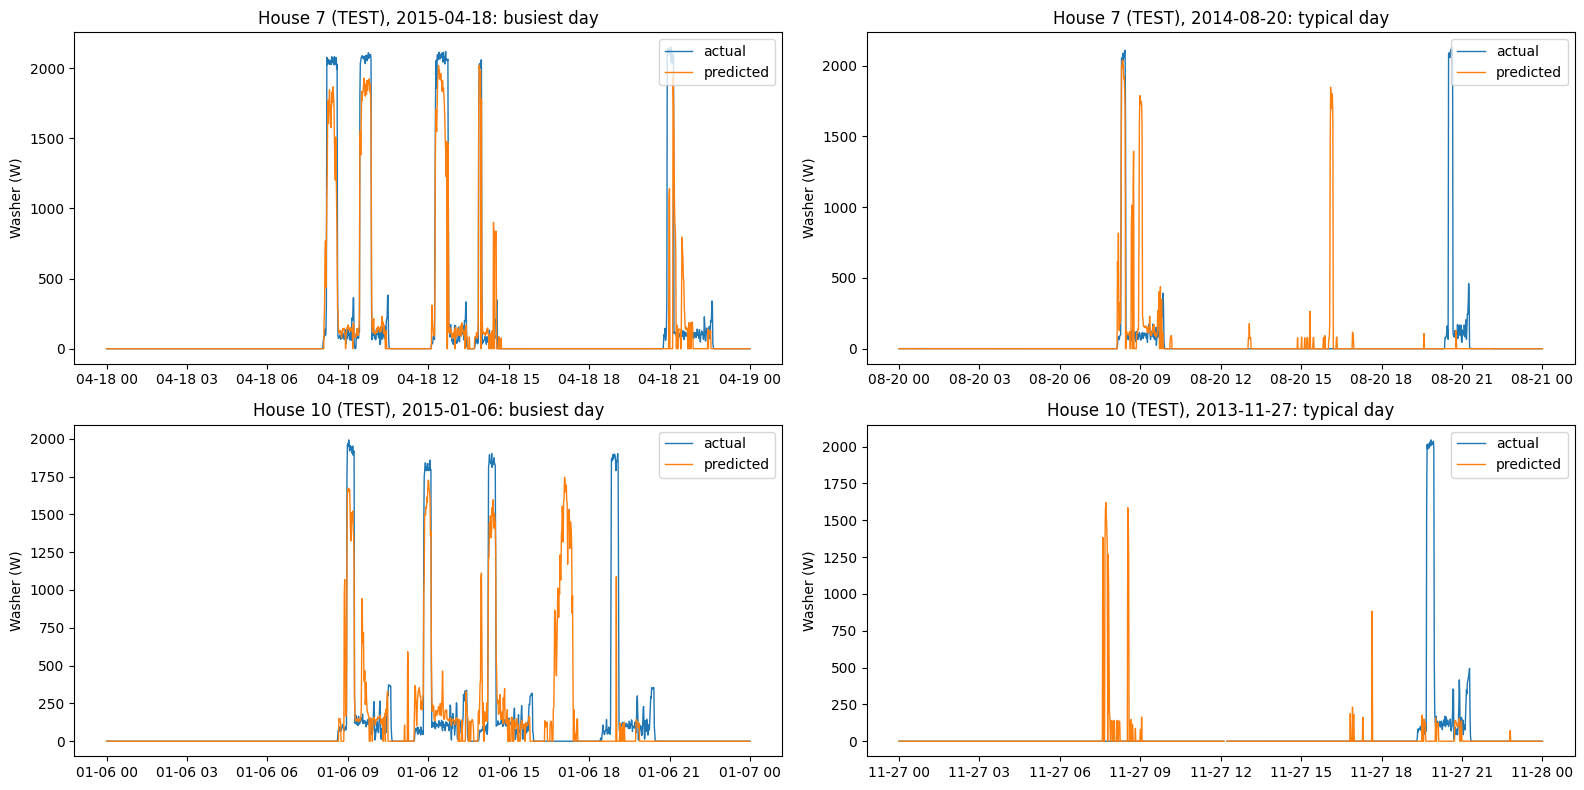

Worst false alarm: House 7, 2013-12-06 18:19:00+00:00 to 2013-12-06 19:04:00+00:00, 950 Wh predicted while washer off


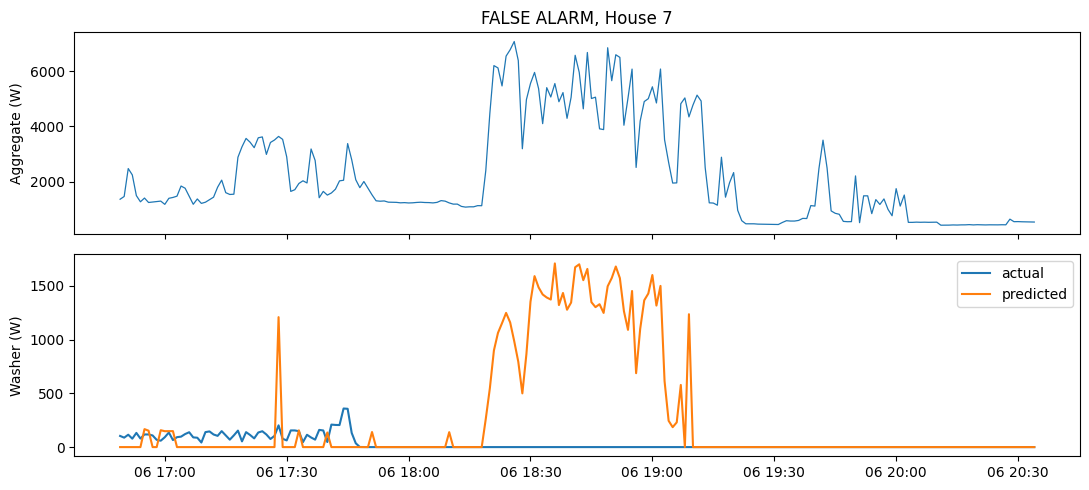

Worst cycle: House 7, 2013-11-26 19:18:00+00:00, true 606 Wh vs predicted 0 Wh


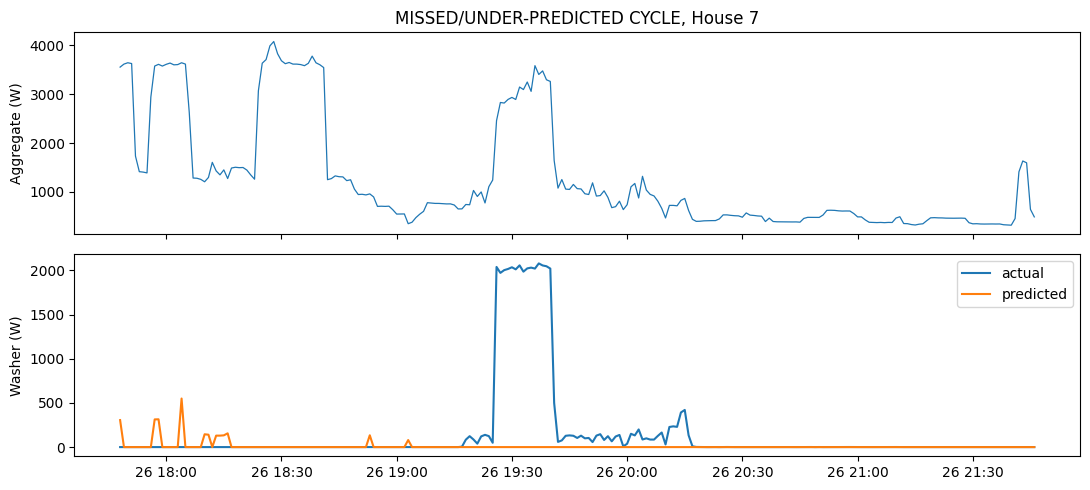


Share of true cycles detected by duration bucket:
7 {Interval(0, 45, closed='right'): 0.89, Interval(45, 90, closed='right'): 0.87, Interval(90, 1000, closed='right'): 0.95}
10 {Interval(0, 45, closed='right'): 0.43, Interval(45, 90, closed='right'): 0.8, Interval(90, 1000, closed='right'): 0.84}


In [51]:
def full_series(h, p):
    s = pd.Series(np.nan, index=DATA[h].index); s.loc[P[h]["idx"]] = p; return s

def cycle_table(h, p):
    d = DATA[h]; s = full_series(h, p)
    dp = d.copy(); dp["wm"] = s
    ct, cp = CYC[h].copy(), detect_cycles(dp)
    hit = lambda a, bs: bool(((bs["start"] <= a["end"]) & (bs["end"] >= a["start"])).any()) if len(bs) else False
    ct["detected"] = [hit(r, cp) for _, r in ct.iterrows()]
    ct["true_wh"] = ct["energy_wh"]
    ct["pred_wh"] = [s.loc[r["start"]:r["end"]].sum() / 60 for _, r in ct.iterrows()]
    prec = np.mean([hit(r, ct) for _, r in cp.iterrows()]) if len(cp) else np.nan
    return ct, {"true_cycles": len(ct), "pred_cycles": len(cp), "cycle_recall": ct["detected"].mean(),
                "cycle_precision": prec,
                "median_abs_energy_err_%": (100 * (ct["pred_wh"] - ct["true_wh"]).abs() / ct["true_wh"]).median()}

CT, rows = {}, []
for name in ["LightGBM regression", "LightGBM two-stage"]:
    for h in TEST_H:
        ct, r = cycle_table(h, P[h]["preds"][name])
        if name == "LightGBM two-stage": CT[h] = ct
        rows.append({"model": name, "house": h, **r})
cyc_res = pd.DataFrame(rows).set_index(["model", "house"]); print(cyc_res.round(2).to_string())
cyc_res.to_csv(OUT3 / "test_cycle_metrics.csv")

# Actual vs predicted (two-stage): busiest day and a typical day per test house
def pick_days(h):
    d = DATA[h].copy(); d.index = d.index.tz_convert(TZ)
    cov = d["ok"].resample("D").mean()
    en = (d["wm"].where(d["ok"]).resample("D").sum() / 60)[cov > 0.95]; en = en[en > 50]
    return en.idxmax(), (en - en.median()).abs().idxmin()

fig, axes = plt.subplots(len(TEST_H), 2, figsize=(16, 4 * len(TEST_H)))
for i, h in enumerate(TEST_H):
    s_true = DATA[h]["wm"].where(DATA[h]["ok"]); s_pred = full_series(h, P[h]["preds"]["LightGBM two-stage"])
    for j, (lab, day) in enumerate(zip(["busiest day", "typical day"], pick_days(h))):
        a, b = day.tz_convert("UTC"), (day + pd.Timedelta(days=1)).tz_convert("UTC")
        ax = axes[i, j]
        ax.plot(s_true.loc[a:b].index.tz_convert(TZ), s_true.loc[a:b].values, lw=1, label="actual")
        ax.plot(s_pred.loc[a:b].index.tz_convert(TZ), s_pred.loc[a:b].values, lw=1, label="predicted")
        ax.set_title(f"House {h} (TEST), {day.date()}: {lab}"); ax.set_ylabel("Washer (W)"); ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig(OUT3 / "actual_vs_pred_test.png", dpi=130); plt.show()

def plot_window(h, p, start, end, title, fname, pad_min=90):
    a, b = start - pd.Timedelta(minutes=pad_min), end + pd.Timedelta(minutes=pad_min)
    d = DATA[h]; s = full_series(h, p)
    fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    ax[0].plot(d["agg"].loc[a:b].index, d["agg"].loc[a:b].values, lw=0.9); ax[0].set_ylabel("Aggregate (W)")
    ax[1].plot(d["wm"].loc[a:b].index, d["wm"].loc[a:b].values, label="actual")
    ax[1].plot(s.loc[a:b].index, s.loc[a:b].values, label="predicted")
    ax[1].set_ylabel("Washer (W)"); ax[1].legend(); ax[0].set_title(title)
    plt.tight_layout(); plt.savefig(OUT3 / fname, dpi=130); plt.show()

# Failure 1: largest false-alarm episode (pred > 200 W while washer off)
best = None
for h in TEST_H:
    s, d = full_series(h, P[h]["preds"]["LightGBM two-stage"]), DATA[h]
    fp = ((s > 200) & (d["wm"] <= ON_W) & d["ok"])
    rid = (fp != fp.shift()).cumsum()
    seg = pd.DataFrame({"p": s.fillna(0).values, "rid": rid.values}, index=d.index)[fp.values]
    if seg.empty: continue
    g = seg.groupby("rid").apply(lambda x: pd.Series({"start": x.index[0], "end": x.index[-1], "wh": x["p"].sum() / 60}))
    r = g.sort_values("wh").iloc[-1]
    if best is None or r["wh"] > best[1]["wh"]: best = (h, r)
h, r = best
print(f"Worst false alarm: House {h}, {r['start']} to {r['end']}, {r['wh']:.0f} Wh predicted while washer off")
plot_window(h, P[h]["preds"]["LightGBM two-stage"], r["start"], r["end"], f"FALSE ALARM, House {h}", "failure_false_alarm.png")

# Failure 2: worst under-predicted real cycle (> 100 Wh)
allc = pd.concat([CT[h].assign(house=h) for h in TEST_H]); allc = allc[allc["true_wh"] > 100]
w = allc.assign(ratio=allc["pred_wh"] / allc["true_wh"]).sort_values("ratio").iloc[0]
print(f"Worst cycle: House {w['house']}, {w['start']}, true {w['true_wh']:.0f} Wh vs predicted {w['pred_wh']:.0f} Wh")
plot_window(int(w["house"]), P[int(w["house"])]["preds"]["LightGBM two-stage"], w["start"], w["end"],
            f"MISSED/UNDER-PREDICTED CYCLE, House {int(w['house'])}", "failure_missed_cycle.png")
print("\nShare of true cycles detected by duration bucket:")
for h in TEST_H:
    c = CT[h]; print(h, c.groupby(pd.cut(c["duration_min"], [0, 45, 90, 1000]))["detected"].mean().round(2).to_dict())

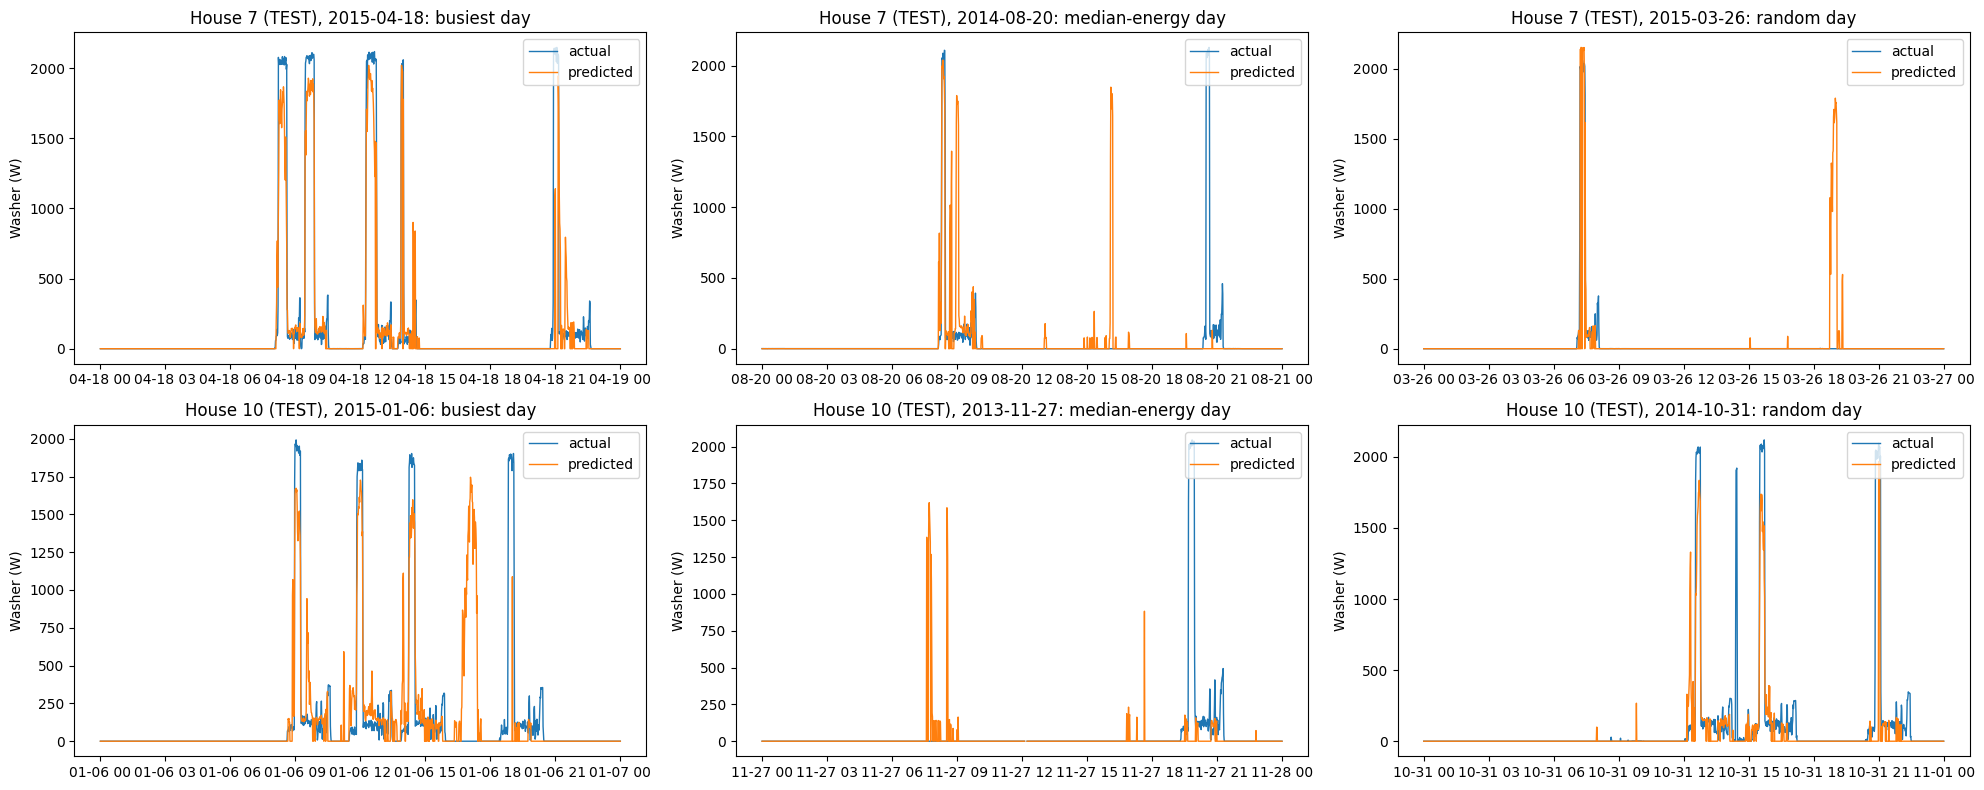

In [53]:
MODEL = "LightGBM two-stage"       # key as used in the final test cell
rng = np.random.default_rng(0)     # fixed seed so the random day is reproducible

def pick_days(h):
    d = DATA[h].copy(); d.index = d.index.tz_convert(TZ)
    cov = d["ok"].resample("D").mean()
    en = (d["wm"].where(d["ok"]).resample("D").sum() / 60)[cov > 0.95]
    en = en[en > 50]                                   # days where the washer actually ran
    busiest = en.idxmax()
    typical = (en - en.median()).abs().idxmin()
    rest = en.index.difference([busiest, typical])
    rand = rest[rng.integers(len(rest))]
    return [("busiest day", busiest), ("median-energy day", typical), ("random day", rand)]

fig, axes = plt.subplots(len(TEST_H), 3, figsize=(20, 4 * len(TEST_H)))
for i, h in enumerate(TEST_H):
    s_true = DATA[h]["wm"].where(DATA[h]["ok"])
    s_pred = full_series(h, P[h]["preds"][MODEL])
    for j, (label, day) in enumerate(pick_days(h)):
        a, b = day.tz_convert("UTC"), (day + pd.Timedelta(days=1)).tz_convert("UTC")
        ax = axes[i, j]
        ax.plot(s_true.loc[a:b].index.tz_convert(TZ), s_true.loc[a:b].values, lw=1, label="actual")
        ax.plot(s_pred.loc[a:b].index.tz_convert(TZ), s_pred.loc[a:b].values, lw=1, label="predicted")
        ax.set_title(f"House {h} (TEST), {day.date()}: {label}")
        ax.set_ylabel("Washer (W)"); ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig(OUT3 / "actual_vs_pred_test.png", dpi=130); plt.show()

In [54]:
import joblib, json
MODEL_DIR = OUT3 / "models"; MODEL_DIR.mkdir(exist_ok=True)

# Portable text format (works across LightGBM versions) + joblib copy of the sklearn wrapper
model.booster_.save_model(str(MODEL_DIR / "lgbm_regressor.txt"))
joblib.dump(model, MODEL_DIR / "lgbm_regressor.joblib")

# Everything needed to reproduce predictions: feature order, thresholds, split, versions
meta = {
    "features": list(Xtr.columns),          # column ORDER must match at prediction time
    "window_each_side_min": BEST_W,
    "cut_W": CUT,
    "on_threshold_W": ON_W,
    "off_keep_in_training": OFF_KEEP,
    "train_houses": TRAIN_H, "val_houses": VAL_H, "test_houses": TEST_H,
    "lightgbm": lgb.__version__, "pandas": pd.__version__,
}
json.dump(meta, open(MODEL_DIR / "model_meta.json", "w"), indent=2)
!ls -lh /kaggle/working/outputs/section3/models

total 592K
-rw-r--r-- 1 root root 293K Oct 29 12:17 lgbm_regressor.joblib
-rw-r--r-- 1 root root 290K Oct 29 12:17 lgbm_regressor.txt
-rw-r--r-- 1 root root  719 Oct 29 12:17 model_meta.json


In [55]:
!cd /kaggle/working && zip -r outputs.zip outputs && ls -lh outputs.zip

  adding: outputs/ (stored 0%)
  adding: outputs/section2/ (stored 0%)
  adding: outputs/section2/washing_machine_summary.csv (deflated 48%)
  adding: outputs/section2/example_cycles.png (deflated 10%)
  adding: outputs/section2/usage_hour_dow.png (deflated 3%)
  adding: outputs/section2/trace_24h.png (deflated 6%)
  adding: outputs/section2/cross_house_comparison.png (deflated 21%)
  adding: outputs/section3/ (stored 0%)
  adding: outputs/section3/actual_vs_pred_test.png (deflated 7%)
  adding: outputs/section3/test_cycle_metrics.csv (deflated 40%)
  adding: outputs/section3/test_results.csv (deflated 55%)
  adding: outputs/section3/failure_missed_cycle.png (deflated 8%)
  adding: outputs/section3/failure_false_alarm.png (deflated 6%)
  adding: outputs/section3/window_ablation_val.csv (deflated 40%)
  adding: outputs/section3/models/ (stored 0%)
  adding: outputs/section3/models/lgbm_regressor.joblib (deflated 59%)
  adding: outputs/section3/models/model_meta.json (deflated 62%)
  add